## Ising GPU Benchmark Suite

Compare the global-memory and shared-memory CUDA implementations across lattice sizes from 32 to 8192, with and without magnetization computation.

In [1]:
import subprocess
from pathlib import Path


def run_cmd(cmd, cwd=None, timeout=600):
    result = subprocess.run(cmd, shell=True, cwd=cwd, capture_output=True, text=True, timeout=timeout)
    return result.returncode, result.stdout, result.stderr

print('Verifying CUDA toolchain...')
nvcc_rc, nvcc_out, nvcc_err = run_cmd('nvcc --version', cwd='/home/steve/projects/ising', timeout=10)
if nvcc_rc != 0:
    raise RuntimeError(f'nvcc not available: {nvcc_err}')
print(nvcc_out)

smi_rc, smi_out, smi_err = run_cmd('nvidia-smi --query-gpu=name,compute_cap --format=csv,noheader', cwd='/home/steve/projects/ising', timeout=10)
if smi_rc != 0:
    raise RuntimeError(f'nvidia-smi not available: {smi_err}')
print(smi_out)
compute_capability = smi_out.strip().split(',')[1].strip().replace('.', '')
print(f'Using sm_{compute_capability} for compilation')

Verifying CUDA toolchain...
nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2023 NVIDIA Corporation
Built on Fri_Jan__6_16:45:21_PST_2023
Cuda compilation tools, release 12.0, V12.0.140
Build cuda_12.0.r12.0/compiler.32267302_0

NVIDIA GeForce GTX 1650 with Max-Q Design, 7.5

Using sm_75 for compilation


In [2]:
import json
import math
import os
import shlex
import time
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

workspace = Path('/home/steve/projects/ising')
results_dir = workspace / 'bench_results'
results_dir.mkdir(exist_ok=True)

def write_text(path, text):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(text)

def read_text(path):
    return Path(path).read_text()

def parse_json_lines(stdout):
    rows = []
    for line in stdout.splitlines():
        line = line.strip()
        if not line:
            continue
        rows.append(json.loads(line))
    return rows

## Benchmark Source

The benchmark binary lives in [bench_ising.cu](bench_ising.cu) and is compiled from this notebook.

In [3]:
benchmark_binary = workspace / 'bench_ising.x'
benchmark_source = workspace / 'bench_ising.cu'

sizes = [32, 64, 128, 256, 512, 1024, 2048, 4096, 8192]
implementations = ['global', 'shared']
mag_modes = [0, 1]
boundary_conditions = ['Periodic']
repeats = 5

def sweeps_for_size(size):
    if size <= 128:
        return 2048
    if size <= 512:
        return 1024
    if size <= 1024:
        return 512
    if size <= 2048:
        return 256
    if size <= 4096:
        return 128
    return 64

sweeps_by_size = {size: sweeps_for_size(size) for size in sizes}
all_rows = []

print('Notebook configuration ready.')
print(f'Results directory: {results_dir}')
print(f'Benchmark binary: {benchmark_binary}')

Notebook configuration ready.
Results directory: /home/steve/projects/ising/bench_results
Benchmark binary: /home/steve/projects/ising/bench_ising.x


## Benchmark Source

The benchmark binary lives in [bench_ising.cu](bench_ising.cu) and is compiled from this notebook.

In [4]:
if not benchmark_source.exists():
    raise FileNotFoundError(f'Missing benchmark source: {benchmark_source}')
print(read_text(benchmark_source).splitlines()[0])
print(f'Found benchmark source: {benchmark_source}')

#include <chrono>
Found benchmark source: /home/steve/projects/ising/bench_ising.cu


## Compile

Build the benchmark executable with nvcc.

In [5]:
compile_cmd = f'nvcc -O3 -std=c++17 -arch=sm_{compute_capability} {shlex.quote(str(benchmark_source))} -o {shlex.quote(str(benchmark_binary))} -lcurand'
print(compile_cmd)
rc, out, err = run_cmd(compile_cmd, cwd=str(workspace), timeout=1200)
if rc != 0:
    print(out)
    print(err)
    raise RuntimeError('Compilation failed')
print(out)
print(f'Compiled binary: {benchmark_binary}')

nvcc -O3 -std=c++17 -arch=sm_75 /home/steve/projects/ising/bench_ising.cu -o /home/steve/projects/ising/bench_ising.x -lcurand

Compiled binary: /home/steve/projects/ising/bench_ising.x


## Benchmark Configuration

Run the benchmark across the requested lattice sizes with an adaptive sweep schedule.

In [6]:
print('Benchmark plan:')
for size in sizes:
    print(f'  size={size:5d}, sweeps={sweeps_by_size[size]:4d}')
print(f'implementations={implementations}')
print(f'mag modes={mag_modes}')
print(f'boundary conditions={boundary_conditions}')
print(f'repeats={repeats}')

Benchmark plan:
  size=   32, sweeps=2048
  size=   64, sweeps=2048
  size=  128, sweeps=2048
  size=  256, sweeps=1024
  size=  512, sweeps=1024
  size= 1024, sweeps= 512
  size= 2048, sweeps= 256
  size= 4096, sweeps= 128
  size= 8192, sweeps=  64
implementations=['global', 'shared']
mag modes=[0, 1]
boundary conditions=['Periodic']
repeats=5


## Run Benchmarks: Pure Updates

This section runs the binary with `--mag 0` so the kernel paths skip magnetization accumulation.

In [7]:
def run_benchmark(impl, bc, size, sweeps, mag, repeats):
    cmd = [
        str(benchmark_binary),
        '--impl', impl,
        '--bc', bc,
        '--size', str(size),
        '--sweeps', str(sweeps),
        '--mag', str(int(mag)),
        '--repeats', str(repeats),
    ]
    rc, out, err = run_cmd(' '.join(shlex.quote(part) for part in cmd), cwd=str(workspace), timeout=7200)
    if rc != 0:
        raise RuntimeError(err or out or 'benchmark failed')
    return parse_json_lines(out)

rows_no_mag = []
for bc in boundary_conditions:
    for impl in implementations:
        for size in sizes:
            sweeps = sweeps_by_size[size]
            print(f'Running {impl} bc={bc} size={size} sweeps={sweeps} mag=0...')
            rows = run_benchmark(impl, bc, size, sweeps, mag=0, repeats=repeats)
            rows_no_mag.extend(rows)
            print(f'  collected {len(rows)} repeat results')

print(f'Collected {len(rows_no_mag)} pure-update rows')

Running global bc=Periodic size=32 sweeps=2048 mag=0...
  collected 5 repeat results
Running global bc=Periodic size=64 sweeps=2048 mag=0...
  collected 5 repeat results
Running global bc=Periodic size=128 sweeps=2048 mag=0...
  collected 5 repeat results
Running global bc=Periodic size=256 sweeps=1024 mag=0...
  collected 5 repeat results
Running global bc=Periodic size=512 sweeps=1024 mag=0...
  collected 5 repeat results
Running global bc=Periodic size=1024 sweeps=512 mag=0...
  collected 5 repeat results
Running global bc=Periodic size=2048 sweeps=256 mag=0...
  collected 5 repeat results
Running global bc=Periodic size=4096 sweeps=128 mag=0...
  collected 5 repeat results
Running global bc=Periodic size=8192 sweeps=64 mag=0...
  collected 5 repeat results
Running shared bc=Periodic size=32 sweeps=2048 mag=0...
  collected 5 repeat results
Running shared bc=Periodic size=64 sweeps=2048 mag=0...
  collected 5 repeat results
Running shared bc=Periodic size=128 sweeps=2048 mag=0...
  

## Run Benchmarks: With Magnetization

This section runs the binary with `--mag 1` so each repeat reports the final magnetization.

In [8]:
rows_with_mag = []
for bc in boundary_conditions:
    for impl in implementations:
        for size in sizes:
            sweeps = sweeps_by_size[size]
            print(f'Running {impl} bc={bc} size={size} sweeps={sweeps} mag=1...')
            rows = run_benchmark(impl, bc, size, sweeps, mag=1, repeats=repeats)
            rows_with_mag.extend(rows)
            print(f'  collected {len(rows)} repeat results')

print(f'Collected {len(rows_with_mag)} magnetization rows')

Running global bc=Periodic size=32 sweeps=2048 mag=1...
  collected 5 repeat results
Running global bc=Periodic size=64 sweeps=2048 mag=1...
  collected 5 repeat results
Running global bc=Periodic size=128 sweeps=2048 mag=1...
  collected 5 repeat results
Running global bc=Periodic size=256 sweeps=1024 mag=1...
  collected 5 repeat results
Running global bc=Periodic size=512 sweeps=1024 mag=1...
  collected 5 repeat results
Running global bc=Periodic size=1024 sweeps=512 mag=1...
  collected 5 repeat results
Running global bc=Periodic size=2048 sweeps=256 mag=1...
  collected 5 repeat results
Running global bc=Periodic size=4096 sweeps=128 mag=1...
  collected 5 repeat results
Running global bc=Periodic size=8192 sweeps=64 mag=1...
  collected 5 repeat results
Running shared bc=Periodic size=32 sweeps=2048 mag=1...
  collected 5 repeat results
Running shared bc=Periodic size=64 sweeps=2048 mag=1...
  collected 5 repeat results
Running shared bc=Periodic size=128 sweeps=2048 mag=1...
  

## Aggregate Results

Build the analysis tables and persist CSV/JSON outputs.

In [9]:
results = rows_no_mag + rows_with_mag
df = pd.DataFrame(results)
df['elapsed_s'] = df['elapsed_ms'] / 1000.0
df['throughput'] = (df['size'] * df['size'] * df['sweeps']) / df['elapsed_s']

agg = df.groupby(['impl', 'bc', 'size', 'mag']).agg({
    'elapsed_ms': ['mean', 'std', 'median'],
    'throughput': ['mean', 'std'],
    'sweeps': 'first'
}).reset_index()
agg.columns = ['_'.join(col).strip('_') if col[1] else col[0] for col in agg.columns]

csv_path = results_dir / 'results.csv'
json_path = results_dir / 'results.json'
df.to_csv(csv_path, index=False)
agg.to_csv(results_dir / 'results_aggregated.csv', index=False)
json_path.write_text(json.dumps(results, indent=2))

print(f'Raw rows: {len(df)}')
print(f'Aggregated rows: {len(agg)}')
print(csv_path)
print(json_path)
agg.head()

Raw rows: 180
Aggregated rows: 36
/home/steve/projects/ising/bench_results/results.csv
/home/steve/projects/ising/bench_results/results.json


,impl,bc,size,mag,elapsed_ms_mean,elapsed_ms_std,elapsed_ms_median,throughput_mean,throughput_std,sweeps_first
0,global,Periodic,32,0,72.46866,29.206389,75.9702,3.358029e+07,1.461186e+07,2048
1,global,Periodic,32,1,273.44340,37.098696,279.2610,7.785106e+06,1.068467e+06,2048
2,global,Periodic,64,0,42.06308,0.766808,41.8092,1.994821e+08,3.626176e+06,2048
3,global,Periodic,64,1,263.23820,38.612067,249.9060,3.234223e+07,4.059995e+06,2048
4,global,Periodic,128,0,107.17470,6.554649,105.3470,3.140207e+08,1.921281e+07,2048


## Analysis

Plot elapsed time, throughput, and global/shared speedup for both magnetization modes.

/home/steve/projects/ising/bench_results/comparison.png


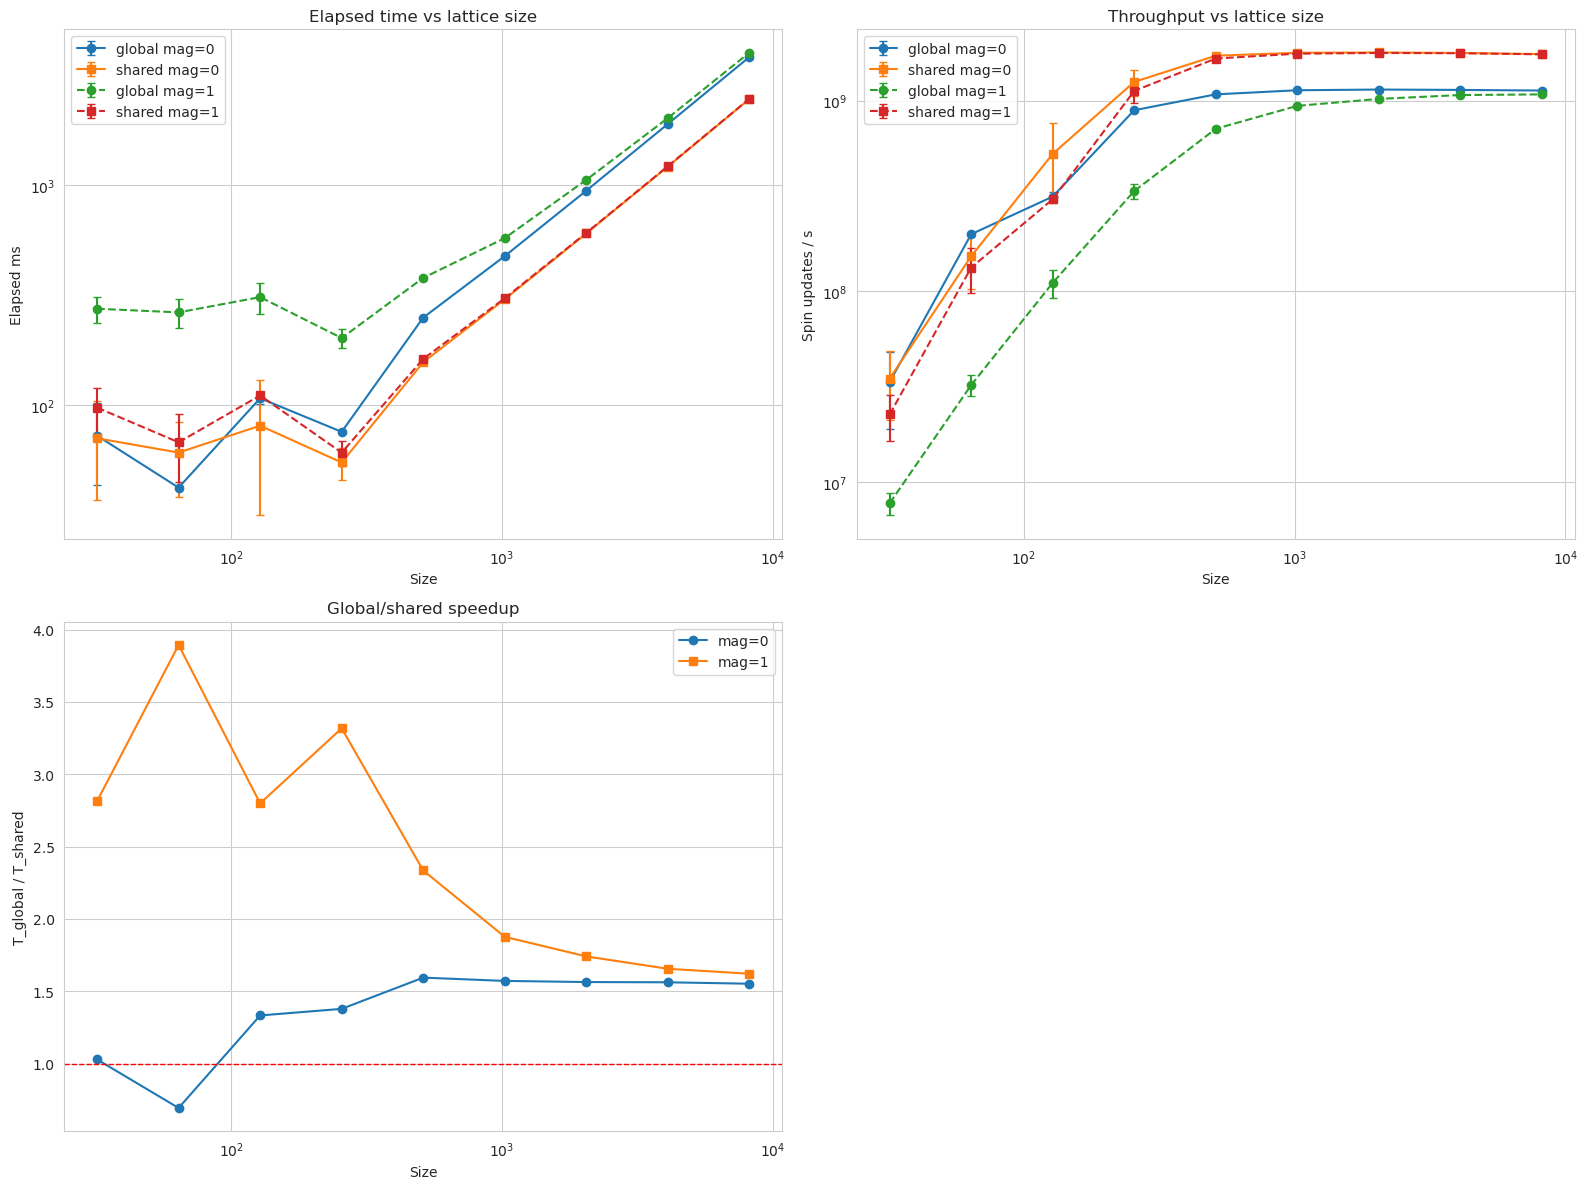

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for mag, linestyle in [(0, '-'), (1, '--')]:
    for impl, marker in [('global', 'o'), ('shared', 's')]:
        subset = agg[(agg['mag'] == mag) & (agg['impl'] == impl)].sort_values('size')
        label = f'{impl} mag={mag}'
        axes[0, 0].errorbar(subset['size'], subset['elapsed_ms_mean'], yerr=subset['elapsed_ms_std'], marker=marker, linestyle=linestyle, capsize=3, label=label)
        axes[0, 1].errorbar(subset['size'], subset['throughput_mean'], yerr=subset['throughput_std'], marker=marker, linestyle=linestyle, capsize=3, label=label)

axes[0, 0].set_xscale('log')
axes[0, 0].set_yscale('log')
axes[0, 0].set_title('Elapsed time vs lattice size')
axes[0, 0].set_xlabel('Size')
axes[0, 0].set_ylabel('Elapsed ms')
axes[0, 0].legend()

axes[0, 1].set_xscale('log')
axes[0, 1].set_yscale('log')
axes[0, 1].set_title('Throughput vs lattice size')
axes[0, 1].set_xlabel('Size')
axes[0, 1].set_ylabel('Spin updates / s')
axes[0, 1].legend()

speedup_rows = []
for bc in boundary_conditions:
    for mag in [0, 1]:
        g = agg[(agg['impl'] == 'global') & (agg['bc'] == bc) & (agg['mag'] == mag)][['size', 'elapsed_ms_mean']].rename(columns={'elapsed_ms_mean': 'global_ms'})
        s = agg[(agg['impl'] == 'shared') & (agg['bc'] == bc) & (agg['mag'] == mag)][['size', 'elapsed_ms_mean']].rename(columns={'elapsed_ms_mean': 'shared_ms'})
        merged = g.merge(s, on='size')
        merged['speedup'] = merged['global_ms'] / merged['shared_ms']
        merged['mag'] = mag
        merged['bc'] = bc
        speedup_rows.append(merged)
speedup_df = pd.concat(speedup_rows, ignore_index=True)
for mag, marker in [(0, 'o'), (1, 's')]:
    subset = speedup_df[speedup_df['mag'] == mag].sort_values('size')
    axes[1, 0].semilogx(subset['size'], subset['speedup'], marker=marker, label=f'mag={mag}')

axes[1, 0].axhline(1.0, color='red', linestyle='--', linewidth=1)
axes[1, 0].set_title('Global/shared speedup')
axes[1, 0].set_xlabel('Size')
axes[1, 0].set_ylabel('T_global / T_shared')
axes[1, 0].legend()

axes[1, 1].axis('off')
plt.tight_layout()
fig_path = results_dir / 'comparison.png'
plt.savefig(fig_path, dpi=160, bbox_inches='tight')
print(fig_path)
plt.show()

## Summary

Show the main tables and save a clean result snapshot.

In [11]:
display(agg.head(20))
print('Mean elapsed time by implementation and magnetization:')
print(agg.groupby(['impl', 'mag'])['elapsed_ms_mean'].mean())
print('Mean throughput by implementation and magnetization:')
print(agg.groupby(['impl', 'mag'])['throughput_mean'].mean())

,impl,bc,size,mag,elapsed_ms_mean,elapsed_ms_std,elapsed_ms_median,throughput_mean,throughput_std,sweeps_first
0,global,Periodic,32,0,72.46866,29.206389,75.9702,3.358029e+07,1.461186e+07,2048
1,global,Periodic,32,1,273.44340,37.098696,279.2610,7.785106e+06,1.068467e+06,2048
2,global,Periodic,64,0,42.06308,0.766808,41.8092,1.994821e+08,3.626176e+06,2048
3,global,Periodic,64,1,263.23820,38.612067,249.9060,3.234223e+07,4.059995e+06,2048
4,global,Periodic,128,0,107.17470,6.554649,105.3470,3.140207e+08,1.921281e+07,2048
5,global,Periodic,128,1,308.82720,49.548035,325.7910,1.109979e+08,1.833731e+07,2048
6,global,Periodic,256,0,75.42342,0.708971,75.6875,8.898247e+08,8.384675e+06,1024
7,global,Periodic,256,1,201.23820,19.663860,192.5580,3.358135e+08,2.989769e+07,1024
8,global,Periodic,512,0,249.17080,0.056251,249.1650,1.077315e+09,2.432146e+05,1024
9,global,Periodic,512,1,377.60020,8.953864,375.0360,7.112170e+08,1.678559e+07,1024


Mean elapsed time by implementation and magnetization:
impl    mag
global  0       850.881118
        1      1005.299956
shared  0       554.400969
        1       564.719942
Name: elapsed_ms_mean, dtype: float64
Mean throughput by implementation and magnetization:
impl    mag
global  0      7.836084e+08
        1      5.890331e+08
shared  0      1.196786e+09
        1      1.143469e+09
Name: throughput_mean, dtype: float64
